# Gamedle: recognising game covers from their degraded versions

[Gamedle](https://gamedle.wtf/classic) shows a degraded game cover and gives six attempts to guess the game; each attempt reveals more of the cover. This notebook trains a model that plays it.

**Formulation: retrieval, not classification.** There is one canonical cover per game and the list of games keeps growing. So the model is an **encoder** that maps an image to a vector such that

    embedding(degraded cover of game X)  ≈  embedding(clean cover of game X)

and a guess is the nearest neighbour in a gallery of clean covers. Adding a new game means embedding one image, with no retraining.

| § | Step | What it does |
|---|------|--------------|
| 1 | Dataset | Downloads ~5.5k covers from IGDB and removes near-duplicates |
| 2 | Degradation | Measures how the site degrades covers, from the site's own files |
| 3 | Split and evaluation protocol | Game-level split: 1,500 test games never seen in training |
| 4 | Baselines | 8×8 colour thumbnail (no learning) and frozen DINOv2 |
| 5 | Model | ConvNeXt-Base + GeM + ArcFace + clean→degraded distillation |
| 6 | Results | Recall@k per attempt, on game files and on simulated screenshots |
| 7 | Playing the real game | The model guessing a real Gamedle round |

Runtime: GPU (Colab or Kaggle T4). Training takes about 55 minutes; if `data/ckpt.pt` exists, the notebook loads it instead of retraining.

## 0. Setup

In [ ]:
import os
import sys

IN_COLAB = 'google.colab' in sys.modules
IN_KAGGLE = os.path.isdir('/kaggle/input')
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
if IN_KAGGLE:
    # Kaggle datasets are read-only: copy src/ and data/ from the attached dataset to the working directory.
    import glob
    import shutil
    for marker, name in [('src/degrade.py', 'src'), ('data/manifest.json', 'data')]:
        found = glob.glob(f'/kaggle/input/**/{marker}', recursive=True)
        if found and not os.path.exists(f'/kaggle/working/{name}'):
            shutil.copytree(os.path.dirname(found[0]), f'/kaggle/working/{name}')
    os.chdir('/kaggle/working')

# Folder that contains src/. Data (covers, masks, checkpoint) lives in PROJECT/data,
# so keeping the project on Google Drive makes it survive Colab restarts.
CANDIDATES = [
    os.getcwd(),
    '/content/drive/MyDrive/gamedle-cover-retrieval',
    '/content/drive/MyDrive/gamedle ia',
    '/content/gamedle-cover-retrieval',
]
PROJECT = next((c for c in CANDIDATES if os.path.isfile(os.path.join(c, 'src', 'degrade.py'))), None)
assert PROJECT, f'src/ not found in any of {CANDIDATES}. Clone the repository or copy it to Google Drive.'
sys.path.insert(0, PROJECT)

DATA = f'{PROJECT}/data'
MASK_DIR = f'{DATA}/masks'
CKPT = f'{DATA}/ckpt.pt'
os.makedirs(DATA, exist_ok=True)
if os.path.isdir(f'{DATA}/mascaras') and not os.path.exists(MASK_DIR):
    os.rename(f'{DATA}/mascaras', MASK_DIR)  # folder name used by earlier runs
print('PROJECT =', PROJECT)


def require(*names):
    """Fails early with a clear message if an earlier cell was not run (e.g. after a Colab restart)."""
    missing = [n for n in names if n not in globals()]
    assert not missing, f"Run the previous cells first (missing: {', '.join(missing)})."

Mounted at /content/drive
PROJECT = /content/drive/MyDrive/gamedle ia


In [ ]:
%pip install -q "timm>=1.0.7"

import torch
import timm

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('torch', torch.__version__, '| timm', timm.__version__, '| device', DEVICE)
if DEVICE == 'cpu':
    print('No GPU found: Runtime > Change runtime type > T4 GPU')

torch 2.14.1+cu130 | timm 1.0.31 | device cuda


## 1. Dataset: covers from IGDB

[IGDB](https://api-docs.igdb.com/) has an official cover per game and a free API (Twitch credentials). The credentials are read from Colab *Secrets* as `TWITCH_ID` and `TWITCH_SECRET`; they are never written in the notebook.

Dataset decisions:
- `rating_count >= 20` filters out obscure games. Asset flips and shovelware have near-identical covers that would inflate the error rate without the model being any worse.
- `game_type = Main Game` excludes DLC, bundles and ports, which reuse the base game's cover: the same image under different labels. (IGDB deprecated the older `category` field; filtering on it silently returns zero games, which is what happened in the first version of this pipeline.)
- Up to 8,000 games were requested, sorted by number of ratings; 5,512 covers were downloaded (`cover_big`, 264×352).

The download runs once; later runs read `data/manifest.json`.

In [ ]:
require('PROJECT')
from src.data import get_twitch_token, fetch_games, download_covers, save_manifest, load_manifest

MANIFEST = f'{DATA}/manifest.json'

# A missing or empty manifest (left by a failed run) triggers a new download.
records = load_manifest(MANIFEST) if os.path.exists(MANIFEST) else []

if not records:
    from google.colab import userdata
    token = get_twitch_token(userdata.get('TWITCH_ID'), userdata.get('TWITCH_SECRET'))
    games = fetch_games(userdata.get('TWITCH_ID'), token, n_games=8000, min_rating_count=20)
    print('games returned by the API:', len(games))
    records = download_covers(games, f'{DATA}/covers', size='cover_big')
    assert records, 'No cover downloaded; the manifest was not saved.'
    save_manifest(records, MANIFEST)

# Paths are rebuilt from DATA so the project folder can be moved.
for r in records:
    r['path'] = f"{DATA}/covers/{r['igdb_id']}.jpg"

print('covers:', len(records))
print(records[0])

covers: 5512
{'igdb_id': 1020, 'name': 'Grand Theft Auto V', 'path': '/content/drive/MyDrive/gamedle ia/data/covers/1020.jpg', 'genres': ['Shooter', 'Racing', 'Adventure'], 'platforms': ['Series X|S', 'PS3', 'PS4', 'PC', 'PS5', 'X360', 'XONE'], 'year': 2013}


### 1.1 Removing near-duplicates

Two visually identical covers with different labels form an impossible decision boundary and make the metric pessimistic for no reason. They are detected with a cheap perceptual hash: the same 8×8 thumbnail used as a baseline in §4.

In [ ]:
require('records')
import numpy as np
from PIL import Image
from tqdm.auto import tqdm
from src.retrieval import thumbnail_descriptor

D = np.stack([thumbnail_descriptor(Image.open(r['path'])) for r in tqdm(records)])
S = D @ D.T
np.fill_diagonal(S, -1)

dupe_pairs = np.argwhere(S > 0.995)
print('near-identical pairs:', len(dupe_pairs) // 2)
for i, j in dupe_pairs[:10:2]:
    print(f'  {records[i]["name"]}  <->  {records[j]["name"]}  (cos={S[i, j]:.4f})')

# keep the first occurrence of each pair
drop = set()
for i, j in dupe_pairs:
    if i not in drop and j not in drop and i < j:
        drop.add(int(j))
records = [r for k, r in enumerate(records) if k not in drop]
print('after deduplication:', len(records))

near-identical pairs: 2
  Assassin's Creed II  <->  Assassin's Creed II: Discovery  (cos=0.9995)
  Mega Man Battle Network 3 Blue  <->  Mega Man Battle Network 3 White  (cos=0.9965)
after deduplication: 5510


## 2. How Gamedle degrades a cover

Whether the model works on the real game depends on simulating the right degradation, and the first guesses were wrong:

1. **Uniform blur.** Wrong: the site does not blur the cover.
2. **A fixed order of revealed tiles**, read from one game. Wrong: on a second game the order and positions were different.
3. **A screenshot** of that second game included the cursor's magnifier, which was read as a game effect: a capture artefact contaminating the data.
4. **Mosaic colour = block mean.** It passed every synthetic test, because the fake "site" in those tests used the same operator as the code. Only real files exposed it: the site uses the block's top-left pixel.

So the degradation is **measured, not assumed**. The site serves pre-rendered files, `<id>_p0.webp` … `<id>_p5.webp` (540×720), one per attempt. §2.2 compares each pixel of those files with the clean cover and with the mosaic and extracts a **mask** with the exact shape of what was revealed. Masks do not depend on the cover's content, so masks measured on real games form a **bank** that training applies to any cover.

What the 21 measured games show:
- **Background:** a mosaic of 50 px blocks (at 540 px width) whose colour is the block's top-left pixel.
- **Revealed regions:** tiles of a 3×3 grid at full resolution, one more per attempt (~11% of the cover each), in an order that changes from game to game. 20 of the 21 games follow this pattern exactly; one (`co3nnx`) shows irregular regions and stronger WebP compression.

using masks measured on 21 real games


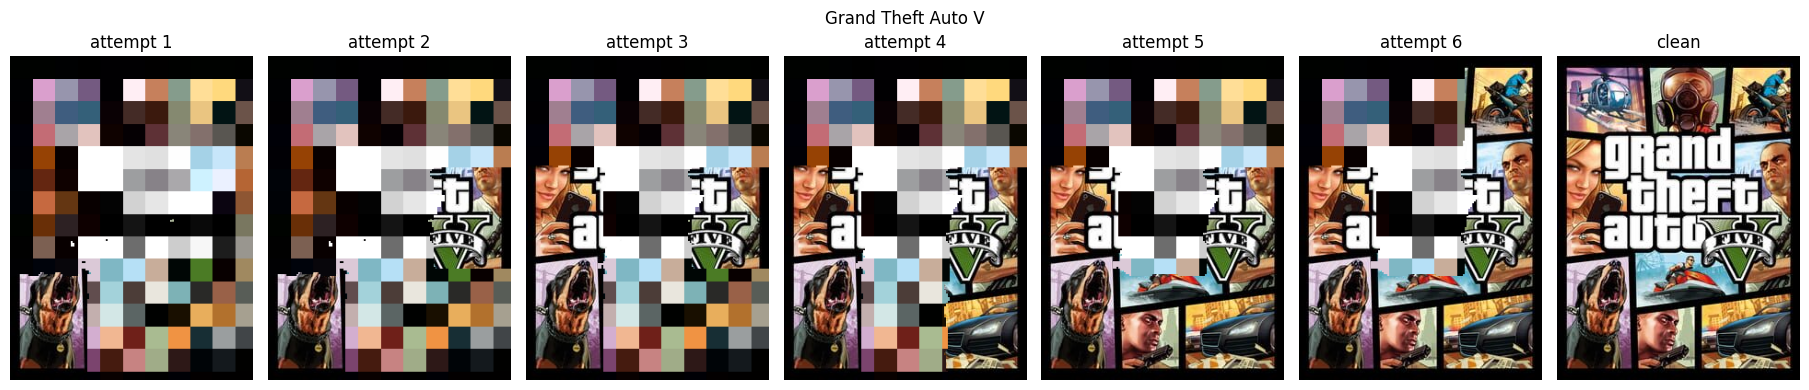

In [ ]:
require('records')
import matplotlib.pyplot as plt
from src.degrade import GamedleDegrader

deg = GamedleDegrader(mask_dir=MASK_DIR)
if len(deg.bank):
    print(f'using masks measured on {len(deg.bank)} real games')
else:
    print('mask bank EMPTY: using random shapes. Run §2.2 first.')

img = Image.open(records[0]['path'])
fig, axes = plt.subplots(1, len(deg) + 1, figsize=(2.6 * (len(deg) + 1), 4))
for lv in range(len(deg)):
    axes[lv].imshow(deg.apply(img, lv)); axes[lv].set_title(f'attempt {lv + 1}'); axes[lv].axis('off')
axes[-1].imshow(img.resize(deg.base_size)); axes[-1].set_title('clean'); axes[-1].axis('off')
plt.suptitle(records[0]['name']); plt.tight_layout(); plt.show()

### 2.1 How much information is left? (Fourier analysis)

The mosaic removes high frequencies, but unlike a blur it is subsampling with aliasing: a block's colour can come from a tiny detail. The revealed tiles keep **all** frequencies, on part of the cover. The plot shows the radial power spectrum at each attempt; even attempt 1 keeps far more high frequency than a uniform blur would.

This also sets a ceiling: if the revealed tile is sky or a flat background, little more than the mosaic is left, and covers with the same colour layout become indistinguishable.

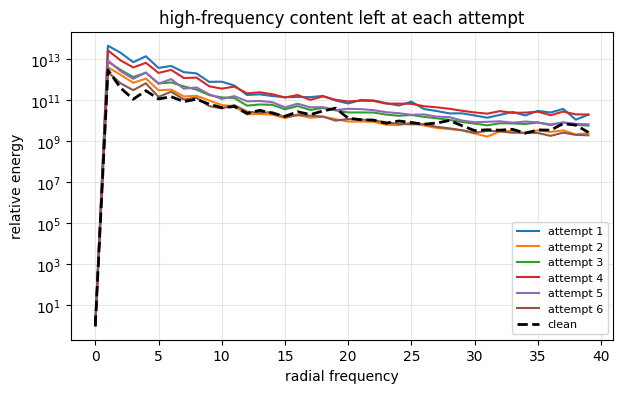

In [ ]:
require('deg', 'img')


def radial_energy(pil_img, bins=40):
    a = np.asarray(pil_img.convert('L').resize((256, 256)), dtype=np.float32) / 255.
    F = np.fft.fftshift(np.fft.fft2(a - a.mean()))
    P = np.abs(F) ** 2
    cy, cx = np.array(P.shape) // 2
    y, x = np.indices(P.shape)
    r = np.sqrt((y - cy) ** 2 + (x - cx) ** 2).astype(int)
    prof = np.bincount(r.ravel(), P.ravel()) / np.maximum(np.bincount(r.ravel()), 1)
    return prof[:bins] / prof[0]


plt.figure(figsize=(7, 4))
for lv in range(len(deg)):
    plt.semilogy(radial_energy(deg.apply(img, lv)), label=f'attempt {lv + 1}')
plt.semilogy(radial_energy(img), 'k--', lw=2, label='clean')
plt.xlabel('radial frequency'); plt.ylabel('relative energy')
plt.title('high-frequency content left at each attempt')
plt.legend(fontsize=8); plt.grid(alpha=.3); plt.show()

### 2.2 Measuring the degradation on the site's files

Each URL below is the image of attempt 1 of a past Gamedle round (right-click on the cover → *Copy image address*). The cell downloads every attempt and two candidate clean covers (IGDB's `t_720p` and the site's own final image), keeps the one that best explains the attempts, and measures the masks with `measure_gamedle` (`src/degrade.py`).

- **Codec.** The site serves WebP, and compression erases fine texture: a sharp grainy area, once compressed, looks like a mosaic block. So both hypotheses (clean cover, mosaic) go through the same codec before the comparison. In synthetic tests this raised the overlap (IoU) between measured and true masks in the last attempts from 0.92 to 0.95–0.99.
- **Quality control.** Pixels that neither hypothesis explains are counted; a game with more than 15% unexplained in any attempt is not added to the bank, since one bad measurement would contaminate training.
- **Label leakage.** The `<id>` in the file name is IGDB's `image_id`, i.e. the answer. It is used here only to find the clean cover; in evaluation and inference the model receives pixels only.

Masks already in the bank are kept; figures are shown for the first three games.

co2e3z: 6 attempts | clean cover: IGDB | mosaic 50 px (corner) | WebP q~95 | revealed: 10% 21% 31% 41% 52% 63% | new regions: 6 (6 rectangular) | max unexplained 7% | already in bank


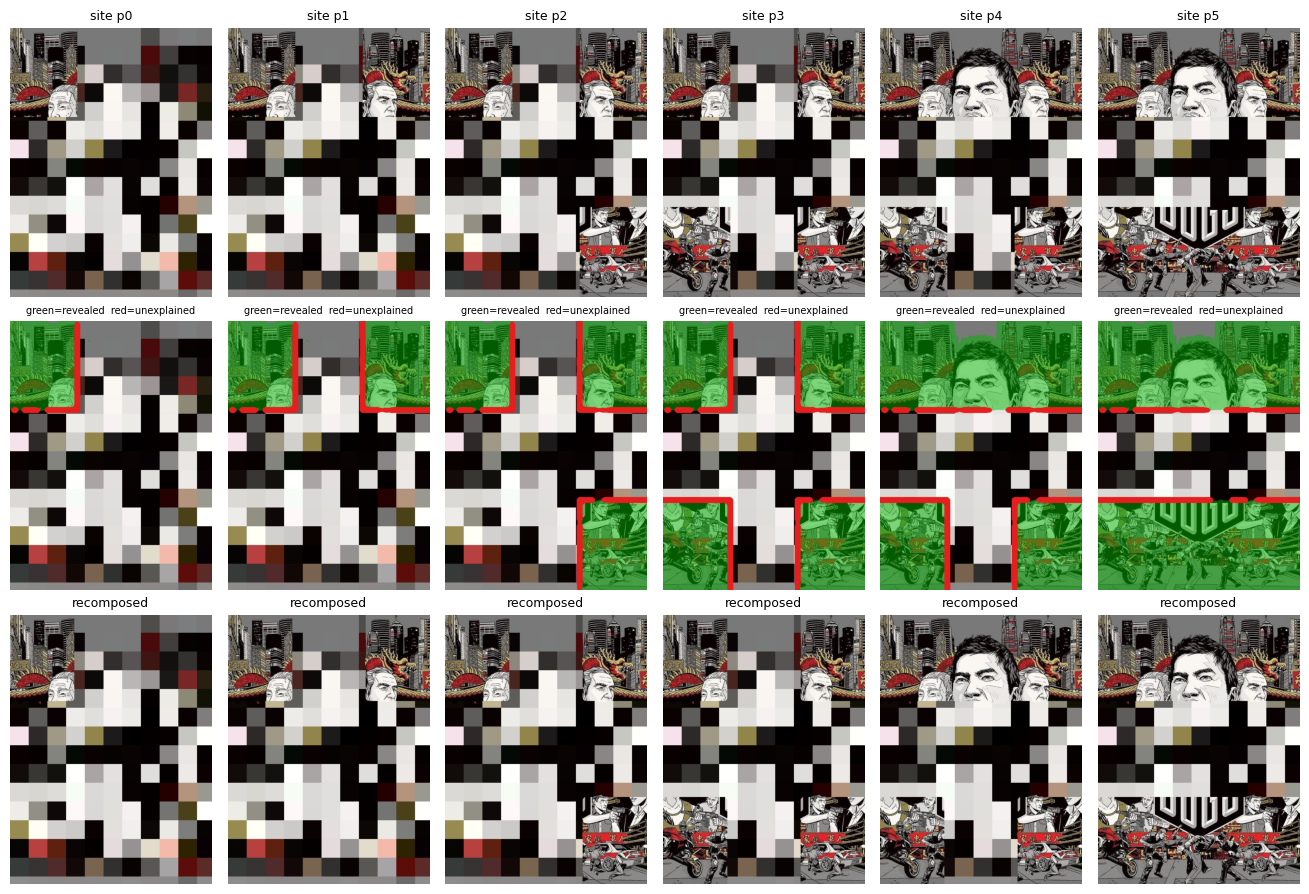

co1u6n: 6 attempts | clean cover: IGDB | mosaic 50 px (corner) | WebP q~95 | revealed: 10% 21% 32% 42% 54% 66% | new regions: 6 (6 rectangular) | max unexplained 4% | already in bank


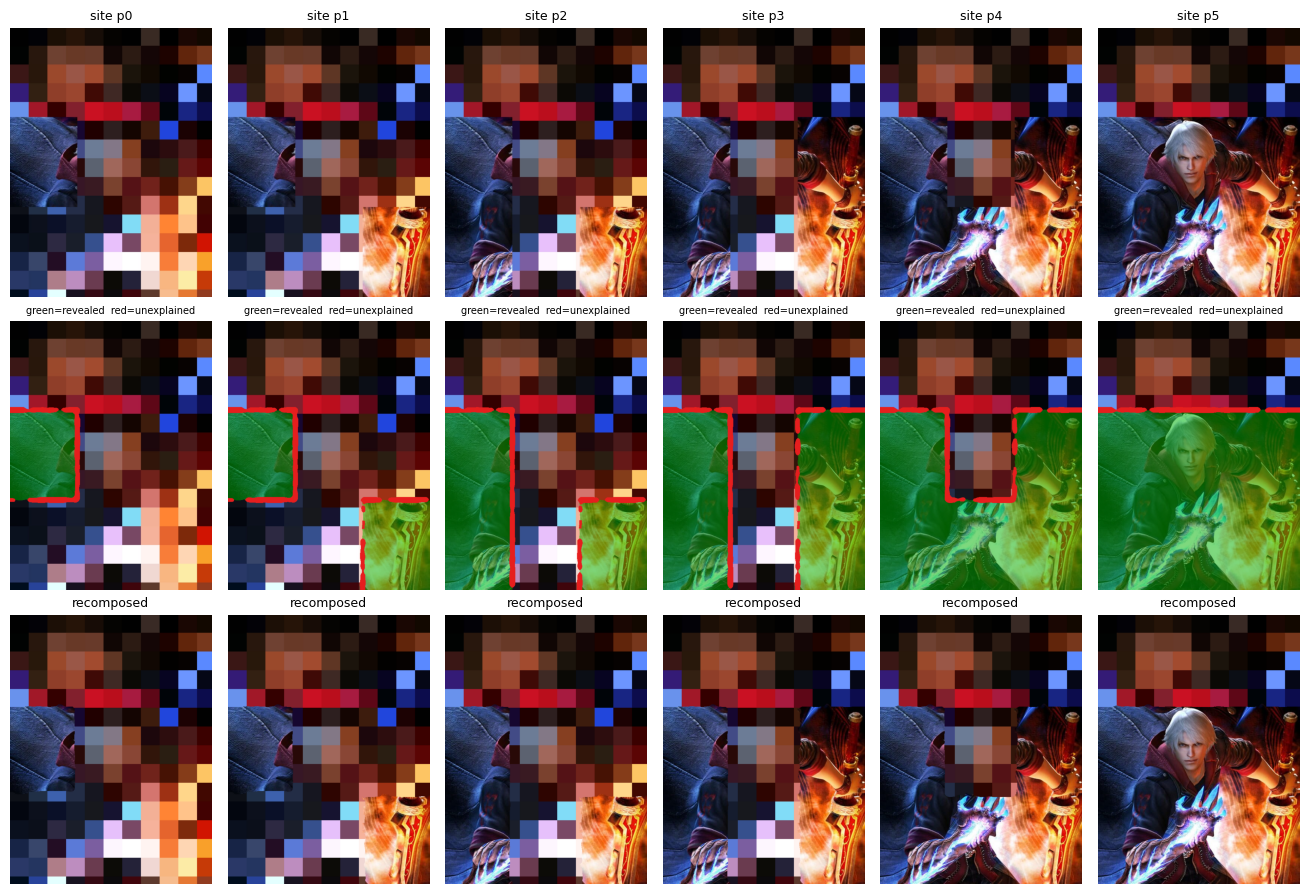

co1wtu: 6 attempts | clean cover: IGDB | mosaic 50 px (corner) | WebP q~95 | revealed: 11% 20% 31% 42% 54% 65% | new regions: 6 (6 rectangular) | max unexplained 4% | already in bank


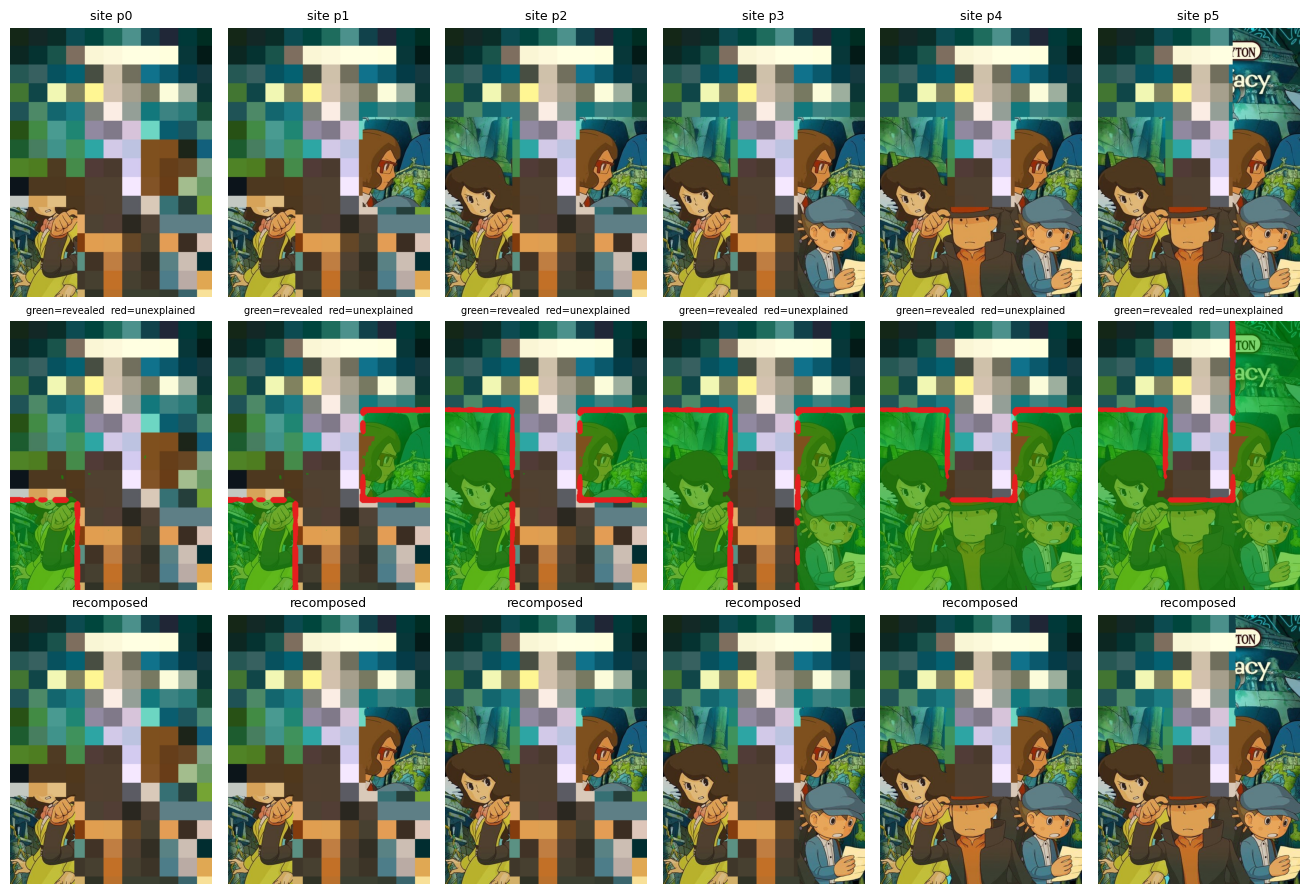

co1qrm: 6 attempts | clean cover: IGDB | mosaic 50 px (corner) | WebP q~95 | revealed: 11% 22% 32% 43% 55% 66% | new regions: 6 (6 rectangular) | max unexplained 3% | already in bank
co2iq1: 6 attempts | clean cover: IGDB | mosaic 50 px (corner) | WebP q~95 | revealed: 10% 21% 32% 43% 54% 65% | new regions: 6 (6 rectangular) | max unexplained 4% | already in bank
co1nsg: 6 attempts | clean cover: IGDB | mosaic 50 px (corner) | WebP q~95 | revealed: 10% 21% 33% 43% 54% 65% | new regions: 6 (6 rectangular) | max unexplained 4% | already in bank
co9qfi: 6 attempts | clean cover: IGDB | mosaic 50 px (corner) | WebP q~95 | revealed: 11% 21% 32% 44% 55% 66% | new regions: 6 (6 rectangular) | max unexplained 2% | already in bank
co3nnx: 6 attempts | clean cover: IGDB | mosaic 50 px (corner) | WebP q~40 | revealed: 13% 15% 18% 20% 27% 35% | new regions: 9 (1 rectangular) | max unexplained 2% | already in bank
co8po2: 6 attempts | clean cover: IGDB | mosaic 50 px (corner) | WebP q~95 | revealed

In [ ]:
require('PROJECT')
import io
import re
import requests
from src.degrade import MaskBank, compose, measure_gamedle

URLS = [
    'https://d2c6c3qulxklrf.cloudfront.net/pixuploaded/covers/co2e3z_p0.webp',
    'https://d2c6c3qulxklrf.cloudfront.net/pixuploaded/covers/co1u6n_p0.webp',
    'https://d2c6c3qulxklrf.cloudfront.net/pixuploaded/covers/co1wtu_p0.webp',
    'https://d2c6c3qulxklrf.cloudfront.net/pixuploaded/covers/co1qrm_p0.webp',
    'https://d2c6c3qulxklrf.cloudfront.net/pixuploaded/covers/co2iq1_p0.webp',
    'https://d2c6c3qulxklrf.cloudfront.net/pixuploaded/covers/co1nsg_p0.webp',
    'https://d2c6c3qulxklrf.cloudfront.net/pixuploaded/covers/co9qfi_p0.webp',
    'https://d2c6c3qulxklrf.cloudfront.net/pixuploaded/covers/co3nnx_p0.webp',
    'https://d2c6c3qulxklrf.cloudfront.net/pixuploaded/covers/co8po2_p0.webp',
    'https://d2c6c3qulxklrf.cloudfront.net/pixuploaded/covers/co93yt_p0.webp',
    'https://d2c6c3qulxklrf.cloudfront.net/pixuploaded/covers/co9rk1_p0.webp',
    'https://d2c6c3qulxklrf.cloudfront.net/pixuploaded/covers/co2t2f_p0.webp',
    'https://d2c6c3qulxklrf.cloudfront.net/pixuploaded/covers/co1p1i_p0.webp',
    'https://d2c6c3qulxklrf.cloudfront.net/pixuploaded/covers/co20bm_p0.webp',
    'https://d2c6c3qulxklrf.cloudfront.net/pixuploaded/covers/co20tq_p0.webp',
    'https://d2c6c3qulxklrf.cloudfront.net/pixuploaded/covers/co2h3y_p0.webp',
    'https://d2c6c3qulxklrf.cloudfront.net/pixuploaded/covers/co5a4y_p0.webp',
    'https://d2c6c3qulxklrf.cloudfront.net/pixuploaded/covers/co1w7q_p0.webp',
    'https://d2c6c3qulxklrf.cloudfront.net/pixuploaded/covers/co1qru_p0.webp',
    'https://d2c6c3qulxklrf.cloudfront.net/pixuploaded/covers/co29i2_p0.webp',
    'https://d2c6c3qulxklrf.cloudfront.net/pixuploaded/covers/co2ip4_p0.webp',
]
MAX_UNEXPLAINED = 0.15   # above this, the measurement is not added to the bank
SHOW_FIGURES = 3


def download(url):
    r = requests.get(url, timeout=30)
    return Image.open(io.BytesIO(r.content)).convert('RGB') if r.ok else None


def worst_unexplained(result):
    return max(l['unexplained_frac'] for l in result['levels'])


for n, url in enumerate(URLS):
    m = re.search(r'^(.*/)([^/_.]+)(?:_p\d+)?\.webp', url.strip())
    assert m, f'Unexpected link format (expected .../<id>_p0.webp or .../<id>.webp): {url}'
    base, image_id = m.group(1), m.group(2)

    attempts = []
    while len(attempts) < 12 and (im := download(f'{base}{image_id}_p{len(attempts)}.webp')) is not None:
        attempts.append(im)
    if not attempts:
        print(f'{image_id}: files no longer available, skipped')
        continue

    # Two candidate clean covers with the same art and size: IGDB's t_720p
    # (probably the site's source) and the site's own copy (one more lossy
    # compression). Which one explains the attempts better is measured.
    result = clean = source = None
    for name, link in [('IGDB', f'https://images.igdb.com/igdb/image/upload/t_720p/{image_id}.jpg'),
                       ('site', f'{base}{image_id}.webp')]:
        candidate = download(link)
        if candidate is None:
            continue
        r = measure_gamedle(attempts, candidate)
        if result is None or worst_unexplained(r) < worst_unexplained(result):
            result, clean, source = r, candidate, name
        if worst_unexplained(r) <= 0.08:
            break
    if result is None:
        print(f'{image_id}: clean cover not found on IGDB or on the site, skipped')
        continue

    L = result['levels']
    shapes = [s['shape'] for l in L for s in l['new_regions']]
    worst = worst_unexplained(result)
    path = f'{MASK_DIR}/{image_id}.npz'
    if worst > MAX_UNEXPLAINED:
        status = 'REJECTED (too much unexplained)'
    elif os.path.exists(path):
        status = 'already in bank'
    else:
        MaskBank.save(path, result['masks'], [l['block_px'] for l in L])
        status = 'added to bank'
    print(f'{image_id}: {len(attempts)} attempts | clean cover: {source} | mosaic {L[0]["block_px"]} px '
          f'({L[0]["sampling"]}) | WebP q~{L[0]["webp_quality"]} | revealed: '
          + ' '.join(f'{l["revealed_frac"]:.0%}' for l in L)
          + f' | new regions: {len(shapes)} ({shapes.count("rectangle?")} rectangular)'
          + f' | max unexplained {worst:.0%} | {status}')

    if n < SHOW_FIGURES:
        fig, ax = plt.subplots(3, len(attempts), figsize=(2.2 * len(attempts), 9), squeeze=False)
        for k, im in enumerate(attempts):
            over = np.asarray(im).copy()
            rev, odd = result['masks'][k], result['unexplained'][k]
            over[rev] = (0.5 * over[rev] + [0, 90, 0]).astype(np.uint8)
            over[odd] = [230, 30, 30]
            ax[0, k].imshow(im); ax[0, k].set_title(f'site p{k}', fontsize=9)
            ax[1, k].imshow(over); ax[1, k].set_title('green=revealed  red=unexplained', fontsize=7)
            ax[2, k].imshow(compose(clean, rev, L[k]['block_px'], L[k]['sampling']))
            ax[2, k].set_title('recomposed', fontsize=9)
            for a in ax[:, k]:
                a.axis('off')
        plt.tight_layout(); plt.show()

bank = MaskBank(MASK_DIR)
print(f'\nmask bank: {len(bank)} games')

The figure below summarises the bank: for each attempt, the fraction of measured games in which each pixel is revealed. A fixed order would show sharp tiles; a random order spreads the probability over the 3×3 grid.

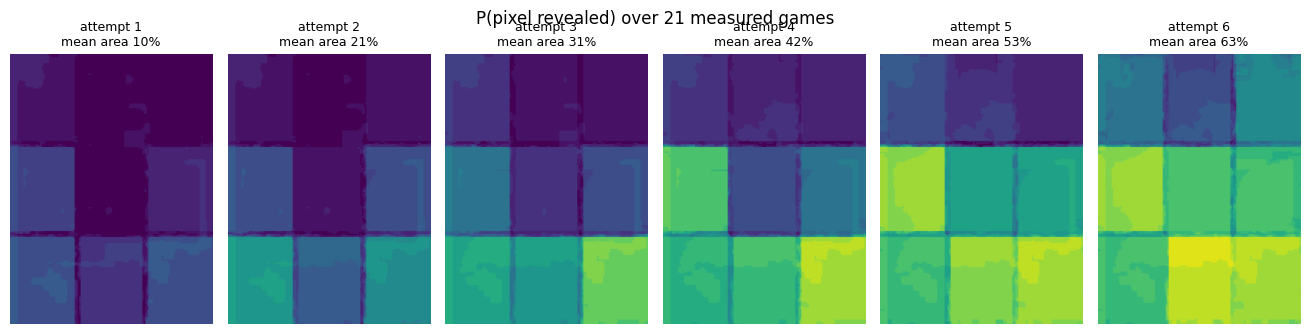

In [ ]:
require('bank')
assert len(bank), 'The mask bank is empty.'
n_att = min(len(masks) for masks, _ in bank.items)
freq = np.stack([np.stack(masks[:n_att]).astype(float) for masks, _ in bank.items]).mean(0)

fig, axes = plt.subplots(1, n_att, figsize=(2.2 * n_att, 3.4))
for k in range(n_att):
    axes[k].imshow(freq[k], vmin=0, vmax=1, cmap='viridis')
    axes[k].set_title(f'attempt {k + 1}\nmean area {freq[k].mean():.0%}', fontsize=9)
    axes[k].axis('off')
plt.suptitle(f'P(pixel revealed) over {len(bank)} measured games'); plt.tight_layout(); plt.show()

deg = GamedleDegrader(mask_dir=MASK_DIR)  # reload with the current bank

## 3. Split and evaluation protocol

The split is by **game**, not by image: the 1,500 test games are classes the model never saw in training. That is the only way to tell whether it learned a similarity space or memorised 4,010 labels.

All methods are evaluated the same way: the gallery holds the clean covers of the 1,500 test games, and each query is attempt *k* of one of them. The degradation in evaluation is deterministic (seeded by the image content), so every method sees exactly the same queries. Two conditions:

- **Game files:** the attempt exactly as the site renders it.
- **Simulated screenshot:** the same attempt with an imprecise crop (up to 6% per side), on-screen rescaling, a brightness change and JPEG re-encoding (`src/screenshot.py`). None of these was used in training, so this measures robustness outside the training distribution, closer to a player pasting a screenshot.

If `data/ckpt.pt` exists, the split is read from it, so the test set is exactly the one held out when the model was trained.

In [ ]:
require('records', 'deg')
import random

N_TEST = 1500
ckpt = torch.load(CKPT, map_location='cpu', weights_only=False) if os.path.exists(CKPT) else None
# weights_only=False: the checkpoint also stores the training records and the history.
# Only load checkpoints you created yourself.

if ckpt is not None:
    train_ids = {r['igdb_id'] for r in ckpt['records']}
    train_records = [r for r in records if r['igdb_id'] in train_ids]
    test_records = [r for r in records if r['igdb_id'] not in train_ids]
else:
    shuffled = records[:]
    random.Random(0).shuffle(shuffled)
    test_records, train_records = shuffled[:N_TEST], shuffled[N_TEST:]

print(f'train: {len(train_records)} games | test (never seen in training): {len(test_records)} games')

train: 4010 games | test (never seen in training): 1500 games


In [ ]:
require('test_records', 'deg')
import pandas as pd
from torch.utils.data import DataLoader
from src.data import GalleryDataset, QueryDataset
from src.retrieval import CoverIndex, embed_loader, mean_reciprocal_rank, recall_at_k, thumbnail_descriptor

N_LEVELS = len(deg)
TRUE = torch.arange(len(test_records))
CONDITIONS = {'game files': False, 'simulated screenshot': True}
results = {}   # results[method][condition] = list of metrics per attempt


def metrics(idx):
    m = recall_at_k(idx, TRUE)
    m['MRR'] = mean_reciprocal_rank(idx, TRUE)
    return m


def evaluate_thumbnail(screenshot):
    gallery = torch.from_numpy(np.stack([thumbnail_descriptor(Image.open(r['path'])) for r in test_records]))
    rows = []
    for lv in range(N_LEVELS):
        ds = QueryDataset(test_records, deg, lv, screenshot=screenshot)
        q = torch.from_numpy(np.stack([thumbnail_descriptor(ds.make(Image.open(r['path']).convert('RGB'), i))
                                       for i, r in enumerate(test_records)]))
        rows.append(metrics((q @ gallery.T).topk(10, dim=-1).indices))
    return rows


def evaluate_model(model, screenshot, batch_size=128):
    gallery = embed_loader(model, DataLoader(GalleryDataset(test_records), batch_size=batch_size, num_workers=2),
                           device=DEVICE)
    index = CoverIndex(gallery, [r['name'] for r in test_records], device=DEVICE)
    rows = []
    for lv in range(N_LEVELS):
        ds = QueryDataset(test_records, deg, lv, screenshot=screenshot)
        q = embed_loader(model, DataLoader(ds, batch_size=batch_size, num_workers=2), device=DEVICE)
        _, idx = index.search(q, topk=10)
        rows.append(metrics(idx))
    return rows


def show(method):
    for cond, rows in results[method].items():
        print(f'{method} | {cond}')
        for lv, m in enumerate(rows):
            print(f'  attempt {lv + 1}: ' + '  '.join(f'{k}={v:.3f}' for k, v in m.items()))

## 4. Baselines

**8×8 thumbnail, no learning.** Each cover is reduced to 8×8 RGB (192 numbers), mean-centred and normalised, and searched by cosine. It captures the low-frequency colour layout, which is most of what the mosaic preserves. Any trained model has to beat it clearly to justify itself.

**Frozen DINOv2.** A ViT-B/14 trained with self-supervision on 142M images, used without fine-tuning. It measures how much of the problem a strong general-purpose model solves for free. Its features rely on local texture and shape, which the mosaic destroys.

In [ ]:
require('evaluate_thumbnail')
results['8x8 thumbnail'] = {cond: evaluate_thumbnail(shot) for cond, shot in CONDITIONS.items()}
show('8x8 thumbnail')

8x8 thumbnail | game files
  attempt 1: R@1=0.990  R@5=0.998  R@10=0.999  MRR=0.993
  attempt 2: R@1=0.993  R@5=0.999  R@10=1.000  MRR=0.996
  attempt 3: R@1=0.997  R@5=0.999  R@10=1.000  MRR=0.998
  attempt 4: R@1=0.999  R@5=1.000  R@10=1.000  MRR=0.999
  attempt 5: R@1=0.999  R@5=1.000  R@10=1.000  MRR=1.000
  attempt 6: R@1=0.999  R@5=1.000  R@10=1.000  MRR=1.000
8x8 thumbnail | simulated screenshot
  attempt 1: R@1=0.977  R@5=0.994  R@10=0.995  MRR=0.984
  attempt 2: R@1=0.986  R@5=0.997  R@10=0.997  MRR=0.990
  attempt 3: R@1=0.993  R@5=0.998  R@10=0.999  MRR=0.995
  attempt 4: R@1=0.997  R@5=0.999  R@10=1.000  MRR=0.998
  attempt 5: R@1=0.999  R@5=1.000  R@10=1.000  MRR=0.999
  attempt 6: R@1=0.999  R@5=1.000  R@10=1.000  MRR=1.000


In [ ]:
require('evaluate_model')
dino = timm.create_model('vit_base_patch14_reg4_dinov2.lvd142m', pretrained=True,
                         num_classes=0, img_size=224).to(DEVICE).eval()
results['DINOv2 (frozen)'] = {cond: evaluate_model(dino, shot) for cond, shot in CONDITIONS.items()}
show('DINOv2 (frozen)')

del dino
if DEVICE == 'cuda':
    torch.cuda.empty_cache()

DINOv2 (frozen) | game files
  attempt 1: R@1=0.145  R@5=0.261  R@10=0.335  MRR=0.195
  attempt 2: R@1=0.429  R@5=0.589  R@10=0.658  MRR=0.500
  attempt 3: R@1=0.651  R@5=0.793  R@10=0.831  MRR=0.709
  attempt 4: R@1=0.822  R@5=0.895  R@10=0.921  MRR=0.854
  attempt 5: R@1=0.911  R@5=0.952  R@10=0.963  MRR=0.928
  attempt 6: R@1=0.962  R@5=0.981  R@10=0.989  MRR=0.971
DINOv2 (frozen) | simulated screenshot
  attempt 1: R@1=0.115  R@5=0.215  R@10=0.279  MRR=0.159
  attempt 2: R@1=0.362  R@5=0.523  R@10=0.603  MRR=0.431
  attempt 3: R@1=0.581  R@5=0.739  R@10=0.796  MRR=0.648
  attempt 4: R@1=0.760  R@5=0.861  R@10=0.891  MRR=0.803
  attempt 5: R@1=0.875  R@5=0.929  R@10=0.946  MRR=0.898
  attempt 6: R@1=0.942  R@5=0.973  R@10=0.980  MRR=0.956


## 5. Model

- **Backbone:** ConvNeXt-Base (ImageNet-22k → 1k) with **GeM pooling** and a 512-d L2-normalised embedding.
- **ArcFace** with sub-centres (s=30, m=0.30, K=2). Softmax learns to separate classes; retrieval needs a space where distance is meaningful. ArcFace normalises features and weights, so the logit is a cosine, and adds an angular margin to the correct class: compact clusters, which is what nearest-neighbour search needs.
- **Clean→degraded distillation:** the clean cover's embedding (teacher, gradient stopped) pulls the degraded cover's embedding (student): `1 − cos(f_degraded, sg(f_clean))`. Unlike ArcFace, this term does not depend on the training classes, so it carries over to unseen games.
- **Curriculum:** training starts at the easiest attempt and opens up to the hardest over 10 epochs; the ArcFace margin warms up over 5.
- **Augmentation:** masks drawn from the measured bank (80%) or random tiles, horizontal mask flips, mosaic block jitter, WebP re-compression, brightness and saturation.

The ArcFace head is used only in training; inference uses the encoder and the gallery.

loaded checkpoint: 4010 training games, 30 epochs, config {'epochs': 30, 'batch_size': 48, 'lr_backbone': 0.0001, 'lr_head': 0.001, 'weight_decay': 0.0001, 'warmup_epochs': 2, 'margin_final': 0.3, 'margin_warmup_epochs': 5, 'w_clean': 0.5, 'w_distill': 1.0, 'label_smoothing': 0.1, 'grad_clip': 5.0, 'amp': True, 'curriculum_epochs': 10}
training time: 53 min


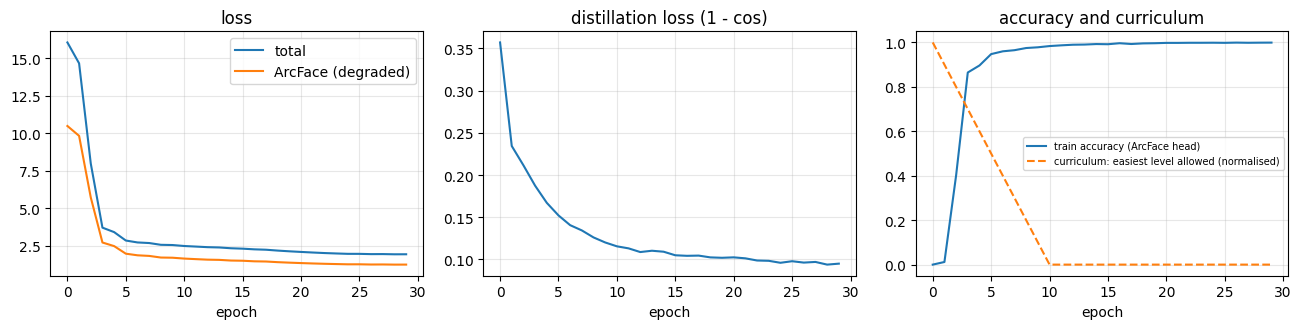

In [ ]:
require('train_records', 'deg')
from src.data import CoverPairDataset
from src.models import ArcFace, CoverEncoder
from src.train import TrainConfig, save_checkpoint, train

BACKBONE = 'convnext_base.fb_in22k_ft_in1k'

if ckpt is None:
    model = CoverEncoder(BACKBONE, embed_dim=512).to(DEVICE)
    head = ArcFace(512, num_classes=len(train_records), scale=30.0, margin=0.30, k=2).to(DEVICE)
    cfg = TrainConfig(epochs=30, batch_size=48, curriculum_epochs=10)
    train_ds = CoverPairDataset(train_records, degrader=deg, img_size=224, train=True)
    history = train(model, head, train_ds, cfg, device=DEVICE, num_workers=2)
    save_checkpoint(CKPT, model, head, train_records, cfg, history)
else:
    model = CoverEncoder(BACKBONE, embed_dim=512, pretrained=False).to(DEVICE)
    model.load_state_dict(ckpt['model'])
    history = ckpt['history']
    print(f"loaded checkpoint: {len(ckpt['records'])} training games, {len(history)} epochs, "
          f"config {ckpt['config']}")
model.eval()

h = pd.DataFrame(history)
print(f"training time: {h['secs'].sum() / 60:.0f} min")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].plot(h['epoch'], h['loss'], label='total'); axes[0].plot(h['epoch'], h['arc'], label='ArcFace (degraded)')
axes[0].set_title('loss'); axes[0].legend()
axes[1].plot(h['epoch'], h['distill']); axes[1].set_title('distillation loss (1 - cos)')
axes[2].plot(h['epoch'], h['train_acc'], label='train accuracy (ArcFace head)')
axes[2].plot(h['epoch'], h['min_level'] / (N_LEVELS - 1), '--', label='curriculum: easiest level allowed (normalised)')
axes[2].set_title('accuracy and curriculum'); axes[2].legend(fontsize=7)
for a in axes:
    a.set_xlabel('epoch'); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6. Results

Recall@k = fraction of test games whose correct cover is among the top *k* guesses; MRR = mean reciprocal rank. Attempt 1 is the hardest (~11% of the cover revealed).

In [ ]:
require('model', 'evaluate_model')
results['ConvNeXt + ArcFace + distillation'] = {cond: evaluate_model(model, shot) for cond, shot in CONDITIONS.items()}
show('ConvNeXt + ArcFace + distillation')

ConvNeXt + ArcFace + distillation | game files
  attempt 1: R@1=0.997  R@5=1.000  R@10=1.000  MRR=0.998
  attempt 2: R@1=0.999  R@5=1.000  R@10=1.000  MRR=1.000
  attempt 3: R@1=0.999  R@5=1.000  R@10=1.000  MRR=1.000
  attempt 4: R@1=1.000  R@5=1.000  R@10=1.000  MRR=1.000
  attempt 5: R@1=1.000  R@5=1.000  R@10=1.000  MRR=1.000
  attempt 6: R@1=1.000  R@5=1.000  R@10=1.000  MRR=1.000
ConvNeXt + ArcFace + distillation | simulated screenshot
  attempt 1: R@1=0.987  R@5=0.999  R@10=1.000  MRR=0.993
  attempt 2: R@1=0.997  R@5=1.000  R@10=1.000  MRR=0.998
  attempt 3: R@1=0.999  R@5=1.000  R@10=1.000  MRR=0.999
  attempt 4: R@1=1.000  R@5=1.000  R@10=1.000  MRR=1.000
  attempt 5: R@1=1.000  R@5=1.000  R@10=1.000  MRR=1.000
  attempt 6: R@1=1.000  R@5=1.000  R@10=1.000  MRR=1.000


Recall@1 on 1500 test games (gallery = the same 1500 clean covers)


,,attempt 1,attempt 2,attempt 3,attempt 4,attempt 5,attempt 6
game files,8x8 thumbnail,99.0%,99.3%,99.7%,99.9%,99.9%,99.9%
simulated screenshot,8x8 thumbnail,97.7%,98.6%,99.3%,99.7%,99.9%,99.9%
game files,DINOv2 (frozen),14.5%,42.9%,65.1%,82.2%,91.1%,96.2%
simulated screenshot,DINOv2 (frozen),11.5%,36.2%,58.1%,76.0%,87.5%,94.2%
game files,ConvNeXt + ArcFace + distillation,99.7%,99.9%,99.9%,100.0%,100.0%,100.0%
simulated screenshot,ConvNeXt + ArcFace + distillation,98.7%,99.7%,99.9%,100.0%,100.0%,100.0%


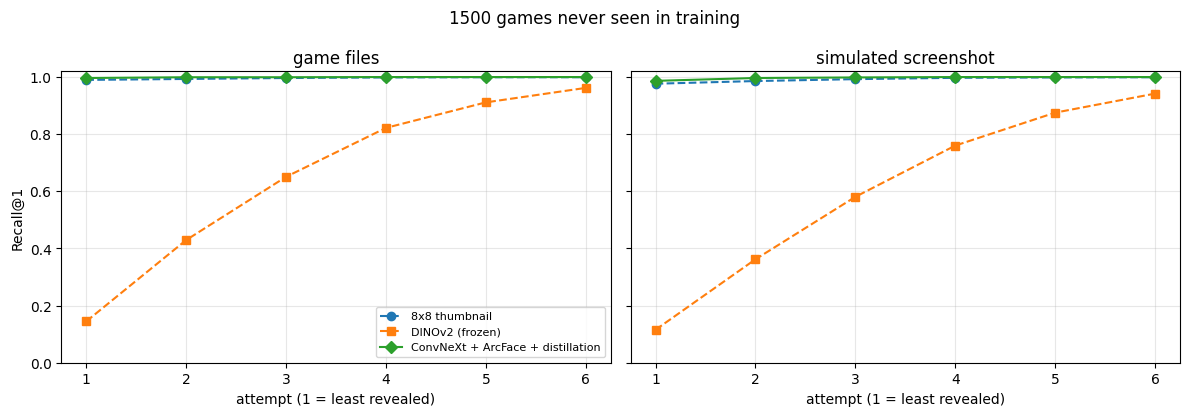

In [ ]:
require('results')
table = pd.DataFrame({
    (cond, method): [m['R@1'] for m in rows]
    for method, by_cond in results.items() for cond, rows in by_cond.items()
}, index=[f'attempt {k + 1}' for k in range(N_LEVELS)]).T
print(f'Recall@1 on {len(test_records)} test games (gallery = the same {len(test_records)} clean covers)')
display(table.style.format('{:.1%}'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
x = range(1, N_LEVELS + 1)
styles = {'8x8 thumbnail': 'o--', 'DINOv2 (frozen)': 's--', 'ConvNeXt + ArcFace + distillation': 'D-'}
for ax, cond in zip(axes, CONDITIONS):
    for method, by_cond in results.items():
        ax.plot(x, [m['R@1'] for m in by_cond[cond]], styles.get(method, 'o-'), label=method)
    ax.set_title(cond); ax.set_xlabel('attempt (1 = least revealed)'); ax.grid(alpha=.3); ax.set_ylim(0, 1.02)
axes[0].set_ylabel('Recall@1'); axes[0].legend(fontsize=8)
plt.suptitle(f'{len(test_records)} games never seen in training'); plt.tight_layout(); plt.show()

**Reading the results.** On the game files the colour thumbnail is already a strong baseline (99.0% at attempt 1): the site renders the attempts from the same IGDB image that is in the gallery, and the corner-sampled mosaic keeps the cover's colour layout, so the task is close to near-duplicate retrieval. The trained model still cuts the errors at attempt 1 by about two thirds (1.0% → 0.3%). The frozen DINOv2, a strong general-purpose model, reaches only 14.5% at attempt 1: its features depend on texture that the mosaic removes, which is why training on the measured degradation matters. With simulated screenshots every method drops, and the trained model stays ahead (98.7% vs 97.7% for the thumbnail at attempt 1). The perturbation used here is mild (crops of up to 6%), so stronger misalignment is the natural next stress test.

### 6.1 Where does it fail?

The errors at attempt 1 (the hardest), with the correct cover and the model's top two guesses.

attempt 1: 5 errors in 1500 games (0.3%); correct game ranked 2nd in 4 of them


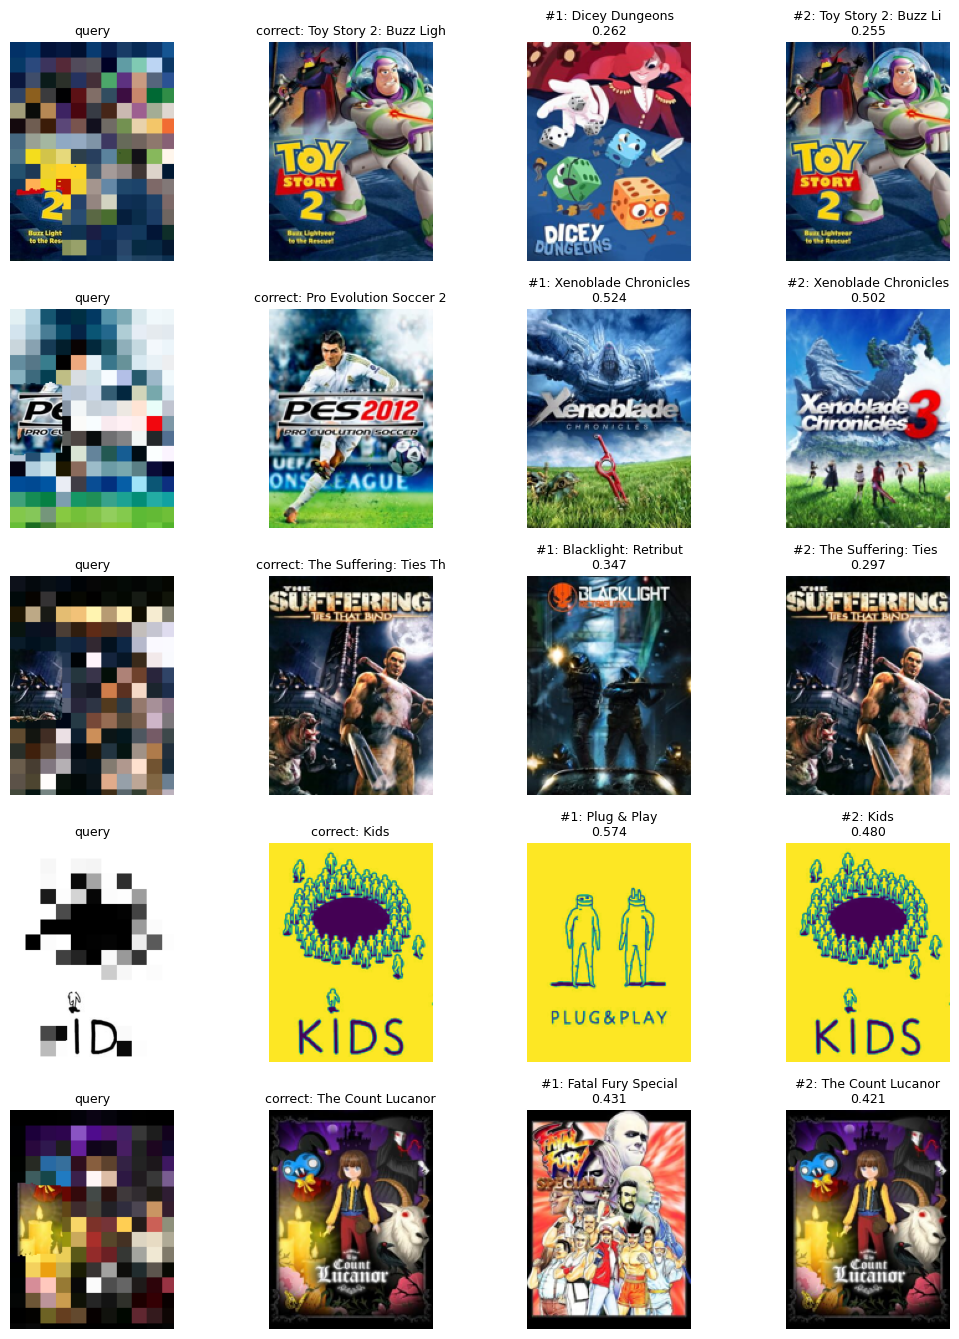

In [ ]:
require('model', 'test_records')
lv = 0
gallery = embed_loader(model, DataLoader(GalleryDataset(test_records), batch_size=128, num_workers=2), device=DEVICE)
index = CoverIndex(gallery, [r['name'] for r in test_records], device=DEVICE)
ds = QueryDataset(test_records, deg, lv)
q = embed_loader(model, DataLoader(ds, batch_size=128, num_workers=2), device=DEVICE)
sc, idx = index.search(q, topk=3)
errors = [i for i in range(len(test_records)) if int(idx[i, 0]) != i]
second = sum(int(idx[i, 1]) == i for i in errors)
print(f'attempt {lv + 1}: {len(errors)} errors in {len(test_records)} games ({len(errors) / len(test_records):.1%}); '
      f'correct game ranked 2nd in {second} of them')

wrong = errors[:6]
if wrong:
    fig, axes = plt.subplots(len(wrong), 4, figsize=(11, 2.7 * len(wrong)), squeeze=False)
    for row, i in enumerate(wrong):
        axes[row, 0].imshow(ds.make(Image.open(test_records[i]['path']).convert('RGB'), i))
        axes[row, 0].set_title('query', fontsize=9)
        axes[row, 1].imshow(Image.open(test_records[i]['path']).resize((132, 176)))
        axes[row, 1].set_title(f'correct: {test_records[i]["name"][:22]}', fontsize=9)
        for c in range(2):
            j = int(idx[i, c])
            axes[row, 2 + c].imshow(Image.open(test_records[j]['path']).resize((132, 176)))
            axes[row, 2 + c].set_title(f'#{c + 1}: {test_records[j]["name"][:20]}\n{float(sc[i, c]):.3f}', fontsize=9)
        for a in axes[row]:
            a.axis('off')
    plt.tight_layout(); plt.show()

## 7. Playing the real game

The final test is the site itself. Paste the address of a Gamedle cover (any attempt) in `LINK`; the cell downloads each attempt and shows the model's top three guesses. The gallery here holds **all** games, not only the test set, since the game of the day can be any of them. The `<id>` in the link is only used to build the file addresses; the model receives pixels only.

gallery: 5510 games


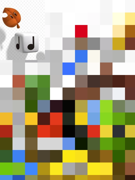

attempt 1: Super Mario 3D Land (0.494) | New Super Mario Bros. 2 (0.332) | Icy Tower (0.285)


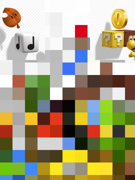

attempt 2: Super Mario 3D Land (0.555) | New Super Mario Bros. 2 (0.388) | de Blob (0.311)


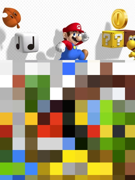

attempt 3: Super Mario 3D Land (0.587) | New Super Mario Bros. 2 (0.356) | Mario Party 3 (0.354)


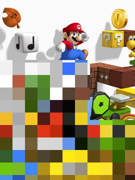

attempt 4: Super Mario 3D Land (0.726) | de Blob (0.370) | Mario Party 3 (0.348)


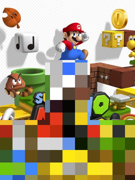

attempt 5: Super Mario 3D Land (0.756) | de Blob (0.351) | Mario Party 3 (0.348)


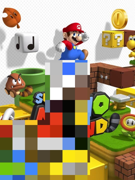

attempt 6: Super Mario 3D Land (0.868) | de Blob (0.368) | Mario Party 3 (0.368)


In [ ]:
require('model', 'records')
import io
import re
import requests
from IPython.display import display
from src.data import to_tensor

LINK = 'https://d2c6c3qulxklrf.cloudfront.net/pixuploaded/covers/co21tq.webp'

if 'full_index' not in globals():
    emb = embed_loader(model, DataLoader(GalleryDataset(records), batch_size=128, num_workers=2), device=DEVICE)
    full_index = CoverIndex(emb, [r['name'] for r in records], device=DEVICE)
print(f'gallery: {len(records)} games')


@torch.no_grad()
def guess(img, topk=3):
    x = to_tensor(img, 224).unsqueeze(0).to(DEVICE)
    with torch.autocast(DEVICE):
        e = model(x)
    return full_index.guess(e.float()[0], topk)


m = re.search(r'^(.*/)([^/_.]+)(?:_p\d+)?\.webp', LINK.strip())
assert m, 'Unexpected link format (expected .../<id>_p0.webp or .../<id>.webp)'
base, image_id = m.group(1), m.group(2)
k = 0
while (r := requests.get(f'{base}{image_id}_p{k}.webp', timeout=30)).ok:
    img = Image.open(io.BytesIO(r.content)).convert('RGB')
    display(img.resize((135, 180)))
    print(f'attempt {k + 1}: ' + ' | '.join(f'{name} ({s:.3f})' for name, s in guess(img)))
    k += 1
assert k, 'No attempt found for this link.'

### 7.1 Guessing from a screenshot

Paste a screenshot (Ctrl+V in the box) or upload a file. A screenshot rarely matches the cover's framing, so the cell tries several crops (`src/screenshot.py`: the whole image, the image without borders, cover-shaped regions and 3:4 windows at three scales) and keeps the one that best matches some cover in the gallery.

In [ ]:
require('model', 'full_index')
import base64
import uuid
from IPython.display import HTML, JSON
from src.screenshot import crop_candidates

MODE = 'paste'   # 'paste': box that accepts Ctrl+V | 'upload': file picker


@torch.no_grad()
def guess_from_screenshot(img, topk=5):
    cands = crop_candidates(img)
    x = torch.stack([to_tensor(c, 224) for c in cands]).to(DEVICE)
    with torch.autocast(DEVICE):
        e = model(x).float()
    scores, idx = full_index.search(e, topk=topk)
    best = int(scores[:, 0].argmax())
    return cands[best], [(full_index.names[int(i)], float(s)) for s, i in zip(scores[best], idx[best])]


PASTE_BOX = """
<div id="zone-UID" contenteditable="true" style="border:2px dashed #888;border-radius:8px;
     padding:28px;text-align:center;font:15px sans-serif;outline:none;caret-color:transparent">
  Click here and press <b>Ctrl+V</b> to paste a screenshot
</div>
<div id="res-UID" style="font:14px sans-serif;margin-top:12px"></div>
<script>
(() => {
  const zone = document.getElementById('zone-UID');
  const res = document.getElementById('res-UID');
  zone.addEventListener('keydown', (ev) => { if (!(ev.ctrlKey || ev.metaKey)) ev.preventDefault(); });
  zone.addEventListener('paste', async (ev) => {
    ev.preventDefault();
    const item = [...ev.clipboardData.items].find((i) => i.type.startsWith('image/'));
    if (!item) { zone.textContent = 'No image in the clipboard.'; return; }
    const raw = await new Promise((ok) => {
      const reader = new FileReader();
      reader.onload = () => ok(reader.result);
      reader.readAsDataURL(item.getAsFile());
    });
    const img = new Image();
    img.src = raw;
    await img.decode();
    const k = Math.min(1, 1400 / Math.max(img.width, img.height));
    const canvas = document.createElement('canvas');
    canvas.width = Math.round(img.width * k);
    canvas.height = Math.round(img.height * k);
    canvas.getContext('2d').drawImage(img, 0, 0, canvas.width, canvas.height);
    zone.textContent = 'Analysing...';
    try {
      const r = await google.colab.kernel.invokeFunction('gamedle.screenshot', [canvas.toDataURL('image/png')], {});
      const d = r.data['application/json'];
      const line = document.createElement('div');
      line.style.cssText = 'display:flex;gap:14px;align-items:flex-start;margin-bottom:14px';
      const thumb = document.createElement('img');
      thumb.src = d.crop;
      thumb.style.border = '1px solid #ccc';
      const list = document.createElement('ol');
      list.style.margin = '0';
      for (const [name, s] of d.guesses) {
        const li = document.createElement('li');
        li.textContent = `${name}  (${s.toFixed(3)})`;
        list.appendChild(li);
      }
      line.append(thumb, list);
      res.prepend(line);
      zone.textContent = 'Done. Paste another screenshot for a new guess.';
    } catch (e) {
      zone.textContent = 'Error: ' + e + ' (set MODE = "upload" and run the cell again)';
    }
  });
})();
</script>
"""

if not IN_COLAB:
    print('The screenshot demo uses Colab widgets: open the notebook in Google Colab to try it.')
elif MODE == 'upload':
    from google.colab import files
    for filename, data in files.upload().items():
        crop, guesses = guess_from_screenshot(Image.open(io.BytesIO(data)).convert('RGB'))
        crop.thumbnail((180, 240))
        print(f'\n{filename}: crop used')
        display(crop)
        for n, (name, s) in enumerate(guesses, 1):
            print(f'  {n}. {name}  ({s:.3f})')
else:
    from google.colab import output

    def _receive(data_url):
        img = Image.open(io.BytesIO(base64.b64decode(data_url.split(',', 1)[1]))).convert('RGB')
        crop, guesses = guess_from_screenshot(img)
        crop.thumbnail((180, 240))
        buf = io.BytesIO()
        crop.save(buf, format='JPEG', quality=90)
        return JSON({'crop': 'data:image/jpeg;base64,' + base64.b64encode(buf.getvalue()).decode(),
                     'guesses': guesses})

    output.register_callback('gamedle.screenshot', _receive)
    display(HTML(PASTE_BOX.replace('UID', uuid.uuid4().hex[:8])))

## 8. Next steps

1. **Train for screenshots.** If the screenshot condition shows a clear drop, add crop, rescaling and JPEG to the training augmentation and measure again.
2. **Several covers per game.** IGDB has regional covers and editions; real intra-class variation is worth more than synthetic augmentation, and it would make the test harder than near-duplicate retrieval.
3. **Use the hints.** After each wrong guess, Gamedle reveals attributes such as genre and platform; filtering the gallery by them before the search is a cheap neural + symbolic combination.
4. **Two-stage re-ranking.** Top-50 by embedding, then a model that looks at query and candidate together.
5. **Higher resolution and backbone ensembles** (288–320 px; ConvNeXt + ViT).

**References**
- Deng et al., *ArcFace: Additive Angular Margin Loss for Deep Face Recognition* (2019).
- Radenović et al., *Fine-tuning CNN Image Retrieval with No Human Annotation* (2018), GeM pooling.
- Oquab et al., *DINOv2: Learning Robust Visual Features without Supervision* (2023).
- Hendrycks & Dietterich, *Benchmarking Neural Network Robustness to Common Corruptions and Perturbations* (2019).